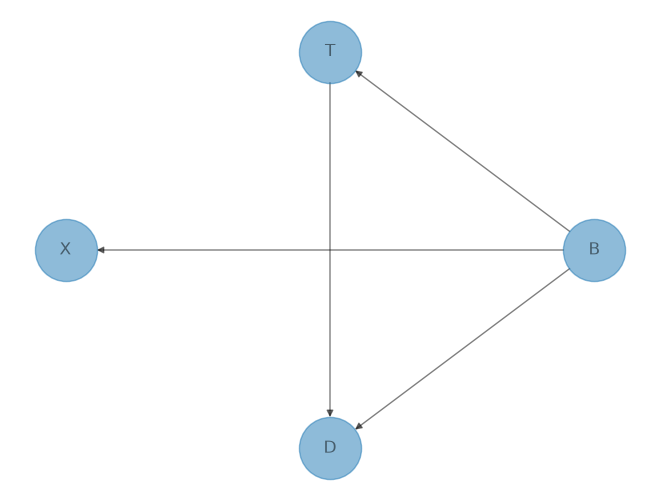

(D ⟂ X | B, T)
(T ⟂ X | B)
(X ⟂ D, T | B)
+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+
+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+


In [11]:
%matplotlib inline
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import matplotlib.pyplot as plt
import itertools

graph = DiscreteBayesianNetwork([('B', 'T'), ('B', 'X'), ('T', 'D'), ('B', 'D')])
pos = nx.circular_layout(graph)
nx.draw(graph, with_labels=True, pos=pos, alpha=0.5, node_size=2000)
independencies = graph.local_independencies(['B','T','D','X'])
plt.show()
print(independencies)

CPD_B = TabularCPD(variable='B', variable_card=2, values=[[0.9], [0.1]])
CPD_T = TabularCPD(variable='T', variable_card=2,
        values=[[0.7, 0.2],
                [0.3, 0.8]],
        evidence=['B'],
        evidence_card=[2])
CPD_X = TabularCPD(variable='X', variable_card=2,
        values=[[0.9, 0.1],
                [0.1, 0.9]],
        evidence=['B'],
        evidence_card=[2])
CPD_D = TabularCPD(variable='D', variable_card=2,
        values=[[0.9, 0.5, 0.6, 0.1],
                [0.1, 0.5, 0.4, 0.9]],
        evidence=['B', 'T'],
        evidence_card=[2, 2])
graph.add_cpds(CPD_B, CPD_T, CPD_X, CPD_D)

infer = VariableElimination(graph)
posterior_b = infer.query(["B"], evidence={"T": 1, "D": 1})
print(posterior_b)
posterior_c = infer.query(["X"], evidence={"B": 0})
print(posterior_c)

In [29]:
import random

def joc():
    first = random.choice([0, 1])
    n = random.randint(1, 6)
    
    if first == 0:
        p_stema = 4 / 7
        m = 0
        for _ in range(2 * n):
            if random.random() < p_stema:
                m += 1
        if n >= m:
            return 0
        else:
            return 1
    else:
        p_stema = 0.5
        m = 0
        for _ in range(2 * n):
            if random.random() < p_stema:
                m += 1
        if n >= m:
            return 1
        else:
            return 0

nr_simulari = 10000
wins_j0 = 0
wins_j1 = 0

for _ in range(nr_simulari):
    castigator = joc()
    if castigator == 0:
        wins_j0 += 1
    else:
        wins_j1 += 1

sansa_j0 = (wins_j0 / nr_simulari) * 100
sansa_j1 = (wins_j1 / nr_simulari) * 100

print(f"Sanse de castig pentru J0: {wins_j0} ({sansa_j0}%)")
print(f"Sanse de castig pentru J1: {wins_j1} ({sansa_j1}%)")

Sanse de castig pentru J0: 4314 (43.14%)
Sanse de castig pentru J1: 5686 (56.86%)


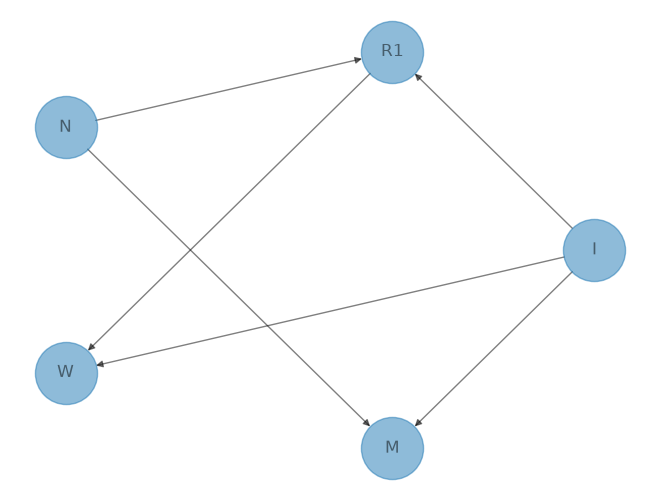

(I ⟂ N)
(M ⟂ R1, W | I, N)
(N ⟂ I)
(R1 ⟂ M | I, N)
(W ⟂ M, N | I, R1)
+------+----------+
| W    |   phi(W) |
+======+==========+
| W(0) |   0.4267 |
+------+----------+
| W(1) |   0.5733 |
+------+----------+
+------+----------+
| I    |   phi(I) |
+======+==========+
| I(0) |   0.4529 |
+------+----------+
| I(1) |   0.5471 |
+------+----------+


In [30]:
%matplotlib inline
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom

graph = DiscreteBayesianNetwork([('I', 'R1'), ('N', 'R1'), ('I', 'W'), ('R1', 'W'), ('I', 'M'), ('N', 'M')])
pos = nx.circular_layout(graph)
nx.draw(graph, with_labels=True, pos=pos, alpha=0.5, node_size=2000)
independencies = graph.local_independencies(['I', 'N', 'R1', 'W', 'M'])
plt.show()
print(independencies)

CPD_I = TabularCPD(variable='I', variable_card=2, values=[[0.5], [0.5]])

CPD_N = TabularCPD(
    variable='N',
    variable_card=6,
    values=[[1/6], [1/6], [1/6], [1/6], [1/6], [1/6]]
)
#binom.cdf -> P(X <= k) // "cumulative distribution function"
p_r1_win_i0 = [binom.cdf(n, 2 * n, 4 / 7) for n in range(1, 7)]
p_r1_win_i1 = [binom.cdf(n, 2 * n, 0.5) for n in range(1, 7)]

vals_r1_win = p_r1_win_i0 + p_r1_win_i1
vals_r1_lose = [1.0 - p for p in vals_r1_win]

CPD_R1 = TabularCPD(
    variable='R1',
    variable_card=2,
    values=[vals_r1_lose, vals_r1_win],
    evidence=['I', 'N'],
    evidence_card=[2, 6]
)

CPD_W = TabularCPD(
    variable='W',
    variable_card=2,
    values=[
        [0.0, 1.0, 1.0, 0.0],
        [1.0, 0.0, 0.0, 1.0]
    ],
    evidence=['I', 'R1'],
    evidence_card=[2, 2]
)

#pct c
vals_m = []
for m in range(13):
    row = []
    for n in range(1, 7):
        #binom.pmf -> P(X = k)  // "probability mass function"
        row.append(binom.pmf(m, 2 * n, 4 / 7))
    for n in range(1, 7):
        row.append(binom.pmf(m, 2 * n, 0.5))
    vals_m.append(row)

CPD_M = TabularCPD(
    variable='M',
    variable_card=13,
    values=vals_m,
    evidence=['I', 'N'],
    evidence_card=[2, 6]
)

graph.add_cpds(CPD_I, CPD_N, CPD_R1, CPD_W, CPD_M)
graph.check_model()

infer = VariableElimination(graph)

posterior_w = infer.query(['W'])
print(posterior_w)

posterior_i = infer.query(['I'], evidence={'M': 1})
print(posterior_i)

In [ ]:
#Problema 1

#Un participant are de ales dintre 3 usi, 2 au in spate o capra si 1 o masina. 
#Dupa ce a ales una, prezentatorul deschide o usa cu o capra, apoi intreaba participantul daca vrea sa isi schimbe decizia.
#La prima vedere, pare ca nu are de ce sa aleaga sa schimbe usa, avand ambele o sansa de 1/2 sa contina masina. 
#De fapt, o data ce se stie ca in a 3-a usa este o capra, sansa de 2/3 pe care o aveau cumulat cele 2 usi nealese de participant initial, 
#se "transfera" spre usa cu care poate face schimb participantul, deci e mai profitabil sa schimbe usa.
#Problema e modelata cu 3 variabile bayesiene, P(prize), C(contestant/participant), H(host). 

In [31]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

# Defining the network structure
model = DiscreteBayesianNetwork([("C", "H"), ("P", "H")])

# Defining the CPDs:
#contestant
cpd_c = TabularCPD("C", 3, [[0.33], [0.33], [0.33]])
#prize
cpd_p = TabularCPD("P", 3, [[0.33], [0.33], [0.33]])
#host / usa pe care o deschide hostul
cpd_h = TabularCPD(
    "H",
    3,
    [
        [0, 0, 0, 0, 0.5, 1, 0, 1, 0.5],
        [0.5, 0, 1, 0, 0, 0, 1, 0, 0.5],
        [0.5, 1, 0, 1, 0.5, 0, 0, 0, 0],
    ],
    evidence=["C", "P"],
    evidence_card=[3, 3],
)

# Associating the CPDs with the network structure.
model.add_cpds(cpd_c, cpd_p, cpd_h)

# Some other methods
model.get_cpds()
model.check_model()
# Infering the posterior probability
from pgmpy.inference import VariableElimination

#𝑃⁡(𝑃|𝐻 =2,𝐶 =0)
infer = VariableElimination(model)
posterior_p = infer.query(["P"], evidence={"C": 0, "H": 2})
print(posterior_p)

+------+----------+
| P    |   phi(P) |
+======+==========+
| P(0) |   0.3333 |
+------+----------+
| P(1) |   0.6667 |
+------+----------+
| P(2) |   0.0000 |
+------+----------+


In [ ]:
P(H | P, C):
+------+------+------+------+------+------+------+------+------+------+
|   C  |          0         |          1         |          2         |
+------+------+------+------+------+------+------+------+------+------+
|   P  |   0  |   1  |   2  |   0  |   1  |   2  |   0  |   1  |   2  |
+------+------+------+------+------+------+------+------+------+------+
|  H=0 |   0  |   0  |   0  |   0  |  0.5 |   1  |   0  |   1  |  0.5 |
+------+------+------+------+------+------+------+------+------+------+
|  H=1 |  0.5 |   0  |   1  |   0  |   0  |   0  |   1  |   0  |  0.5 |
+------+------+------+------+------+------+------+------+------+------+
|  H=2 |  0.5 |   1  |   0  |   1  |  0.5 |   0  |   0  |   0  |   0  |
+------+------+------+------+------+------+------+------+------+------+